In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

simulator = AerSimulator()
SHOTS = 100
print("Setup complete!")

Setup complete!


# Challenge 3: Can you change the correlation?
**Participant:** POLAMARASETTY JAGADEESH  
**Institution:** Vishnu Institute of Technology  

### Predictions
- **Original Bell State (|Phi+>):** Expect only '00' and '11' with ~50% probability each.
- **Modified State (|Psi+>):** Adding an X gate on q1 inverts the correlation, yielding predominantly '01' and '10' (~50% each).

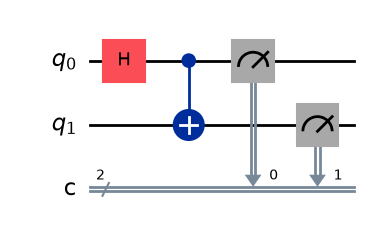

Original counts: {'11': 45, '00': 55}


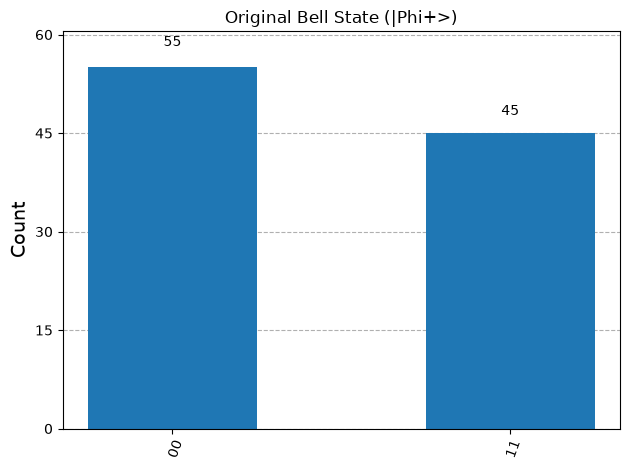

In [2]:
# Original Bell-State Circuit
qc_orig = QuantumCircuit(2, 2)
qc_orig.h(0)
qc_orig.cx(0, 1)
qc_orig.measure([0, 1], [0, 1])

display(qc_orig.draw('mpl'))

job_orig = simulator.run(qc_orig, shots=SHOTS)
counts_orig = job_orig.result().get_counts()
print("Original counts:", counts_orig)
display(plot_histogram(counts_orig, title="Original Bell State (|Phi+>)"))

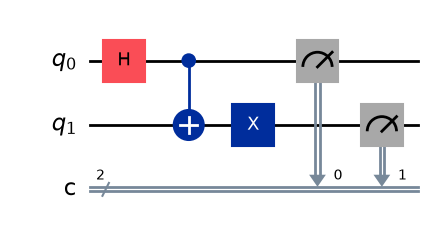

Modified counts: {'01': 48, '10': 52}


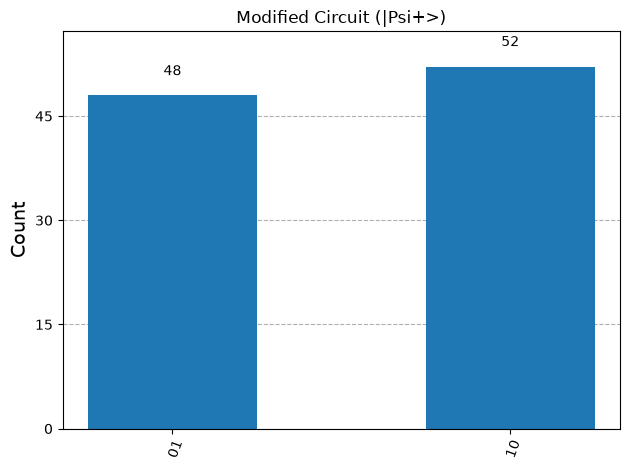

In [3]:
# Modified Circuit with X gate on qubit 1
qc_mod = QuantumCircuit(2, 2)
qc_mod.h(0)
qc_mod.cx(0, 1)
qc_mod.x(1)  # Modify correlation
qc_mod.measure([0, 1], [0, 1])

display(qc_mod.draw('mpl'))

job_mod = simulator.run(qc_mod, shots=SHOTS)
counts_mod = job_mod.result().get_counts()
print("Modified counts:", counts_mod)
display(plot_histogram(counts_mod, title="Modified Circuit (|Psi+>)"))

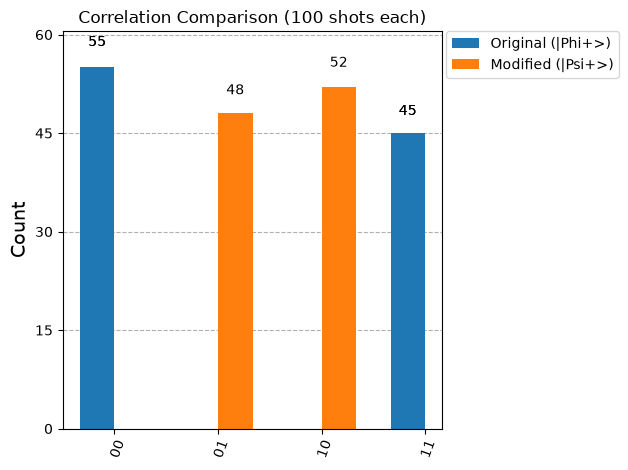

In [4]:
# Comparative Histogram
display(plot_histogram([counts_orig, counts_mod], 
                       legend=['Original (|Phi+>)', 'Modified (|Psi+>)'],
                       title="Correlation Comparison (100 shots each)"))

### Summary
The original circuit produces identical measurement pairs ('00' and '11'). Applying an X gate on qubit 1 applies a bit-flip that converts the output to complementary pairs ('01' and '10'), inverting the observed correlation.